In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pingouin as pg
import seaborn as sns
from pathlib import Path
from datetime import datetime
import os
import re, sys

# Load data 
- x - predicted probability of the gt label: gt_confidence
- y - plausibility score: msfi, fp. FP is feature portion, which is the portion of heatmap inside the annotated lesion mask. 
- XAI - name of XAI algorithm
- Fold - different model training using random seeds
- faithfulness - XAI faithfulness of a model (Fold 1-5)

In [2]:
msfi_fp_brain = pd.read_csv('../data/msfi_fp_brain.csv') # plausibility data of the brain task
faithfulness = pd.read_csv('../data/acc_drop_bg_brain.csv') # faithfulness data of the brain task

/Users/root202/Software/anaconda3/envs/posthoc-eval/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.1, the latest is 0.5.3.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(
/Users/root202/Software/anaconda3/envs/posthoc-eval/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package outdated is out of date. Your version is 0.2.1, the latest is 0.2.2.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [3]:
# get faithfulness ranking using means from the models of five folds
faithfulness_dict = dict(faithfulness.groupby(['method'])['diffAUC'].mean())
faithfulness_rank = dict(sorted(faithfulness_dict.items(), key=lambda x:x[1], reverse=True))
faithfulness_rank

{'GuidedGradCAM': 0.5276576576576576,
 'GuidedBackProp': 0.5259009009009008,
 'Lime': 0.5111711711711713,
 'ShapleyValueSampling': 0.5109189189189189,
 'SmoothGrad': 0.47931531531531535,
 'Deconvolution': 0.37842342342342344,
 'FeatureAblation': 0.34036936936936935,
 'KernelShap': 0.3059639639639639,
 'GradCAM': 0.2211711711711712,
 'Occlusion': 0.20864864864864865,
 'IntegratedGradients': 0.18079279279279273,
 'GradientShap': 0.17559459459459453,
 'DeepLift': 0.162072072072072,
 'InputXGradient': 0.15883783783783775,
 'Gradient': 0.08611711711711714,
 'FeaturePermutation': -0.025000000000000057}

In [4]:
faithfulness

,Unnamed: 0,fold,method,AUC,baseline AUC,diffAUC
0,0,1,IntegratedGradients,0.577027,0.886306,0.309279
1,1,1,GradientShap,0.585811,0.887928,0.302117
2,2,1,KernelShap,0.303378,0.627162,0.323784
3,3,1,Occlusion,0.488514,0.765270,0.276757
4,4,1,GuidedGradCAM,0.285135,0.788378,0.503243
...,...,...,...,...,...,...
75,75,5,DeepLift,0.787838,0.865450,0.077613
76,76,5,SmoothGrad,0.234459,0.753288,0.518829
77,77,5,Deconvolution,0.549324,0.854820,0.305495
78,78,5,GradCAM,0.573649,0.719279,0.145631


# Relationship between misleading explanation and plausibility as criterion

In [3]:
# calculate the percentage of misleading explanations. Misleading explanation is defined by the instance reside that 
# 1. square: gt_confidence < 0.25 and plausbility > 0.75, or:
# 2. triangle: plausibility - gt_confidence > 0.75
msfi_fp_brain['fp'].describe(), msfi_fp_brain['gt_confidence'].describe()
msfi_fp_brain['misleading_square'] = msfi_fp_brain.apply(lambda row: 1 if row['gt_confidence'] < 0.25 and row['fp'] > 0.75 else 0,  axis=1)
msfi_fp_brain['misleading_triangle'] = msfi_fp_brain.apply(lambda row: 1 if row['fp'] - row['gt_confidence'] > 0.75 else 0,  axis=1)

In [4]:
misleading_square_percent = dict(msfi_fp_brain.groupby(['XAI'])['misleading_square'].mean())
misleading_triangle_percent = dict(msfi_fp_brain.groupby(['XAI'])['misleading_triangle'].mean())
misleading_triangle_count = dict(msfi_fp_brain.groupby(['XAI'])['misleading_triangle'].sum())
misleading_square_count = dict(msfi_fp_brain.groupby(['XAI'])['misleading_square'].sum())
fp_mean = dict(msfi_fp_brain.groupby(['XAI'])['fp'].mean())
plausibility_rank = dict(sorted(fp_mean.items(), key=lambda x:x[1], reverse=True))
misleading_dict = [misleading_square_percent, misleading_triangle_percent, misleading_triangle_count, misleading_square_count, fp_mean]
misleading_plausibility = pd.DataFrame.from_records(misleading_dict, index = ['misleading_square_percent', 'misleading_triangle_percent', 'misleading_triangle_count', 'misleading_square_count','fp_mean'])
misleading_plausibility = misleading_plausibility.transpose()

In [7]:
misleading_plausibility

,misleading_square_percent,misleading_triangle_percent,misleading_triangle_count,misleading_square_count,fp_mean
Deconvolution,0.000000,0.000000,0.0,0.0,0.333461
DeepLift,0.029730,0.027027,10.0,11.0,0.621978
FeatureAblation,0.002703,0.002703,1.0,1.0,0.448548
FeaturePermutation,0.002703,0.002703,1.0,1.0,0.171412
GradCAM,0.000000,0.000000,0.0,0.0,0.017835
Gradient,0.000000,0.000000,0.0,0.0,0.300168
GradientShap,0.021622,0.018919,7.0,8.0,0.555878
GuidedBackProp,0.021622,0.018919,7.0,8.0,0.561325
GuidedGradCAM,0.032432,0.029730,11.0,12.0,0.582532
InputXGradient,0.021622,0.016216,6.0,8.0,0.566730


In [6]:
# test for assumption of Pearson correlation: normal distribution
pg.normality(misleading_plausibility['misleading_triangle_percent']), pg.normality(misleading_plausibility['fp_mean'])

(                                    W      pval  normal
 misleading_triangle_percent  0.779939  0.001493   False,
                 W      pval  normal
 fp_mean  0.921368  0.177449    True)

In [8]:
pg.pairwise_corr(data = misleading_plausibility, columns = ['misleading_square_percent','fp_mean'])

,X,Y,method,alternative,n,r,CI95%,p-unc,BF10,power
0,misleading_square_percent,fp_mean,pearson,two-sided,16,0.852805,"[0.62, 0.95]",0.000027,929.301,0.996541


In [9]:
# test of assumption for pearson correlation failed on normality test, use nonparametric test instead
pg.pairwise_corr(data = misleading_plausibility, columns = ['misleading_triangle_percent','fp_mean'])

,X,Y,method,alternative,n,r,CI95%,p-unc,BF10,power
0,misleading_triangle_percent,fp_mean,pearson,two-sided,16,0.844055,"[0.6, 0.94]",0.000039,672.563,0.99516


In [7]:
# Spearman correlation for reporting
pg.pairwise_corr(data = misleading_plausibility, columns = ['misleading_triangle_percent','fp_mean'], method='spearman')

,X,Y,method,alternative,n,r,CI95%,p-unc,power
0,misleading_triangle_percent,fp_mean,spearman,two-sided,16,0.840034,"[0.59, 0.94]",0.000047,0.994405


<Axes: xlabel='fp_mean', ylabel='misleading_square_percent'>

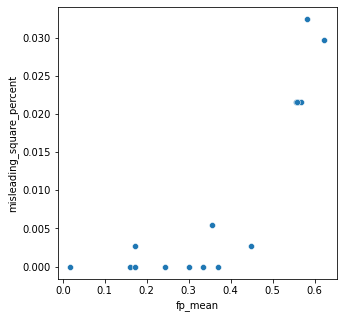

In [10]:
plt.figure(figsize=(5,5))

sns.scatterplot(data = misleading_plausibility, x = 'fp_mean', y = 'misleading_square_percent')

<Axes: xlabel='fp_mean', ylabel='misleading_triangle_percent'>

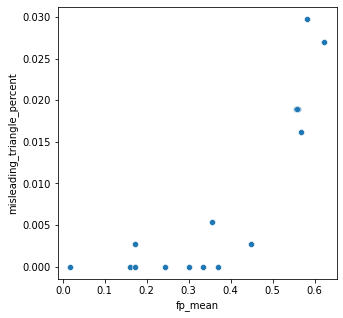

In [11]:
plt.figure(figsize=(5,5))

sns.scatterplot(data = misleading_plausibility, x = 'fp_mean', y = 'misleading_triangle_percent')

In [10]:
plausibility_rank

{'DeepLift': 0.6219778672541881,
 'GuidedGradCAM': 0.5825324474212418,
 'InputXGradient': 0.5667296650810041,
 'GuidedBackProp': 0.5613253237267343,
 'IntegratedGradients': 0.5587380001069129,
 'GradientShap': 0.5558775591151159,
 'FeatureAblation': 0.44854815913792195,
 'ShapleyValueSampling': 0.36910499650749024,
 'SmoothGrad': 0.35631015978099123,
 'Deconvolution': 0.33346081943920974,
 'Gradient': 0.3001679345016758,
 'Occlusion': 0.24415869714636776,
 'Lime': 0.17260682705689118,
 'FeaturePermutation': 0.17141155438061642,
 'KernelShap': 0.16093742761225965,
 'GradCAM': 0.017834741472796733}

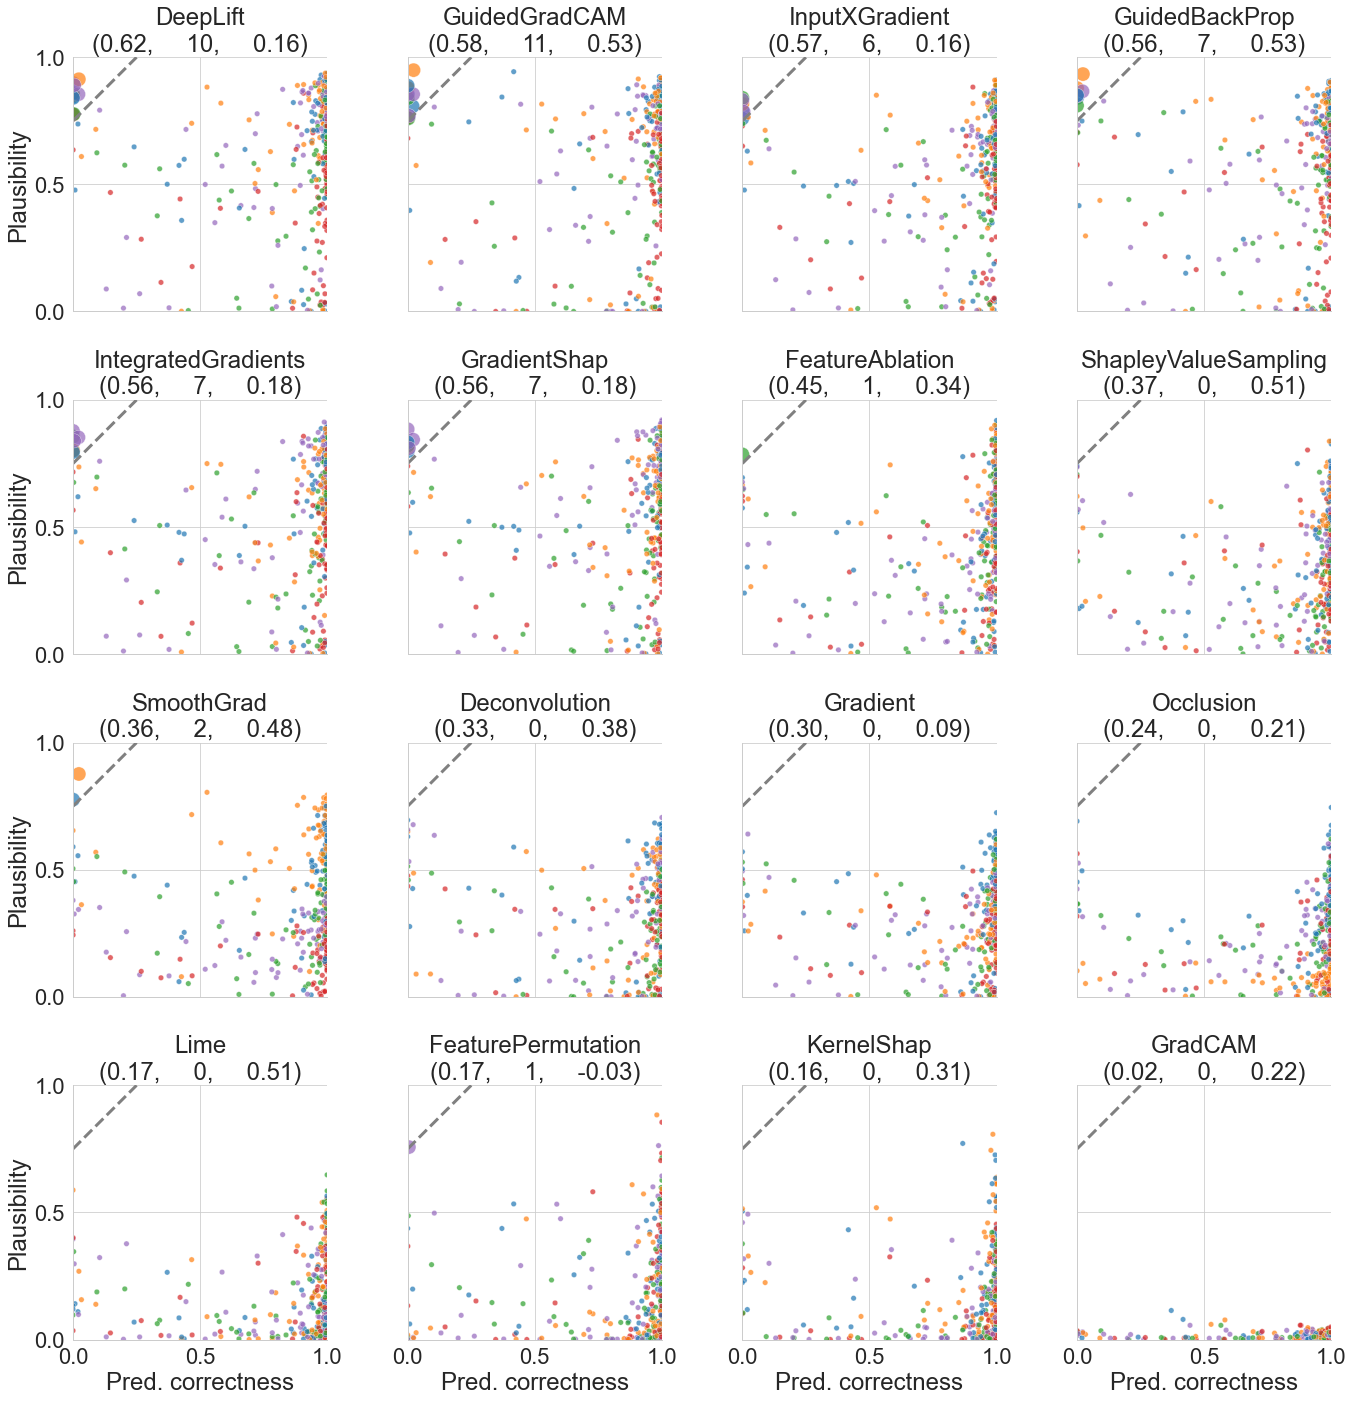

In [13]:
# plot
sns.set_style("whitegrid")
with sns.plotting_context("paper", font_scale=2.5):
    g1 = sns.relplot(
        data=msfi_fp_brain, x='gt_confidence', y='fp',  hue= 'Fold', palette = "tab10",
        size = 'misleading_triangle',sizes=[30, 200],alpha=0.7, legend=False,
        kind='scatter', col='XAI', col_wrap=4, col_order= list(plausibility_rank.keys())
    )
    for ax in g1.axes:
        ax.axline((0, 0.75), (0.25, 1), ls='--', linewidth=3, color='gray')
        ax.set_box_aspect(1)
    for i, ax in enumerate(g1.axes.flat):
        ax.set_title('{}\n({:.2f},     {:.0f},     {:.2f})'.format(
            list(plausibility_rank.keys())[i],
            list(plausibility_rank.values())[i],
            misleading_triangle_count[list(plausibility_rank.keys())[i]],
            faithfulness_dict[list(plausibility_rank.keys())[i]]
                    ))
#     g1.set_titles("{col_name}")
    g1.set(xlim=(0, 1), ylim=(0, 1), xticks=[0, .5, 1], yticks=[0, .5, 1])
    g1.set_axis_labels('Pred. correctness', "Plausibility")
    g1.tight_layout(w_pad=0.05)
#     g1._legend.set_title('Model')

#     g1._legend.remove()
    # save figure
    dateTimeObj = datetime.now()
    time_stamp = dateTimeObj.strftime("%Y%m%d_%H%M")
    fig_name = '{}-{}.pdf'.format('rethinking_plausibility_correctness_dist', time_stamp)
#     g1.savefig(Path('../data')/ fig_name, bbox_inches="tight")


# Testing the hypothesis on generalization of plausibility performance

In [8]:
msfi_fp_knee = pd.read_csv('../data/msfi_fp_knee.csv') # plausibility data for the knee classification task
msfi_fp_knee_dropna = msfi_fp_knee.dropna()
msfi_fp_knee_dropna

,Unnamed: 0,dataID,Fold,XAI,msfi,fp,gt,pred,RW,pred_confidence,gt_confidence
0,0,1130,6,Deconvolution,0.189035,0.171841,0.0,0.018847,True,0.981153,0.981153
1,1,1130,6,FeatureAblation,0.094538,0.114935,0.0,0.018847,True,0.981153,0.981153
2,2,1130,6,Gradient,0.202784,0.188122,0.0,0.018847,True,0.981153,0.981153
3,3,1130,6,GradientShap,0.207209,0.168347,0.0,0.018847,True,0.981153,0.981153
4,4,1130,6,GuidedBackProp,0.214642,0.194139,0.0,0.018847,True,0.981153,0.981153
...,...,...,...,...,...,...,...,...,...,...,...
7315,7315,1249,10,KernelShap,0.154103,0.205499,1.0,0.044436,False,0.955564,0.044436
7316,7316,1249,10,Lime,0.157039,0.213218,1.0,0.044436,False,0.955564,0.044436
7317,7317,1249,10,Occlusion,0.145127,0.158534,1.0,0.044436,False,0.955564,0.044436
7318,7318,1249,10,ShapleyValueSampling,0.147461,0.236305,1.0,0.044436,False,0.955564,0.044436


## 1. Plausibility calculated for the model architecture

Test data from the five models will be aggregated as one mean plausibility

In [9]:
fp_mean_knee = dict(msfi_fp_knee_dropna.groupby(['XAI'])['fp'].mean())
plausibility_rank_knee = dict(sorted(fp_mean_knee.items(), key=lambda x:x[1], reverse=True))
plausibility_rank_knee

{'GuidedBackProp': 0.2516125180075566,
 'Gradient': 0.2495141149063905,
 'SmoothGrad': 0.2487628999352455,
 'InputXGradient': 0.23535053240756193,
 'Deconvolution': 0.2305338606486718,
 'GradientShap': 0.23003845556328695,
 'IntegratedGradients': 0.22709297883522864,
 'ShapleyValueSampling': 0.20466822998725154,
 'Occlusion': 0.19951797793308892,
 'FeatureAblation': 0.18907598763916814,
 'Lime': 0.184105046208327,
 'KernelShap': 0.17370351701742034}

In [10]:
# plausibility_rank of the brain task
plausibility_rank

{'DeepLift': 0.6219778672541881,
 'GuidedGradCAM': 0.5825324474212418,
 'InputXGradient': 0.5667296650810041,
 'GuidedBackProp': 0.5613253237267343,
 'IntegratedGradients': 0.5587380001069129,
 'GradientShap': 0.5558775591151159,
 'FeatureAblation': 0.44854815913792195,
 'ShapleyValueSampling': 0.36910499650749024,
 'SmoothGrad': 0.35631015978099123,
 'Deconvolution': 0.33346081943920974,
 'Gradient': 0.3001679345016758,
 'Occlusion': 0.24415869714636776,
 'Lime': 0.17260682705689118,
 'FeaturePermutation': 0.17141155438061642,
 'KernelShap': 0.16093742761225965,
 'GradCAM': 0.017834741472796733}

In [11]:
corr_plausibility = pd.DataFrame.from_records([fp_mean_knee, fp_mean], index = ['knee', 'brain'])
corr_plausibility = corr_plausibility.transpose().dropna()
corr_plausibility

,knee,brain
Deconvolution,0.230534,0.333461
FeatureAblation,0.189076,0.448548
Gradient,0.249514,0.300168
GradientShap,0.230038,0.555878
GuidedBackProp,0.251613,0.561325
InputXGradient,0.235351,0.566730
IntegratedGradients,0.227093,0.558738
KernelShap,0.173704,0.160937
Lime,0.184105,0.172607
Occlusion,0.199518,0.244159


<Axes: xlabel='knee', ylabel='brain'>

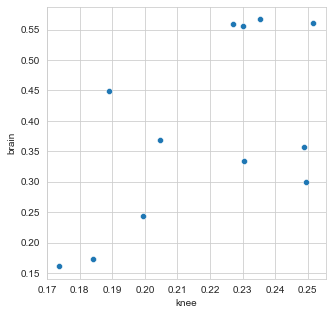

In [19]:
plt.figure(figsize=(5,5))

sns.scatterplot(data = corr_plausibility, x = 'knee', y = 'brain')

In [12]:
# test for assumption of Pearson correlation: normal distribution
pg.normality(corr_plausibility['brain']), pg.normality(corr_plausibility['knee'])

(              W      pval  normal
 brain  0.896591  0.143332    True,
             W      pval  normal
 knee  0.91219  0.227574    True)

In [20]:
# Use Pearson Correlation
pg.pairwise_corr(data = corr_plausibility, columns = ['brain', 'knee'])

,X,Y,method,alternative,n,r,CI95%,p-unc,BF10,power
0,brain,knee,pearson,two-sided,12,0.582934,"[0.01, 0.87]",0.04667,2.101,0.544173


In [23]:
corr_plausibility_long = pd.melt(corr_plausibility.reset_index(), id_vars='index')
corr_plausibility_long

,index,variable,value
0,Deconvolution,knee,0.230534
1,FeatureAblation,knee,0.189076
2,Gradient,knee,0.249514
3,GradientShap,knee,0.230038
4,GuidedBackProp,knee,0.251613
5,InputXGradient,knee,0.235351
6,IntegratedGradients,knee,0.227093
7,KernelShap,knee,0.173704
8,Lime,knee,0.184105
9,Occlusion,knee,0.199518


In [36]:
common_plausibility_rank = {k:plausibility_rank[k] for k in list(plausibility_rank.keys()) if k in list(plausibility_rank_knee.keys())}

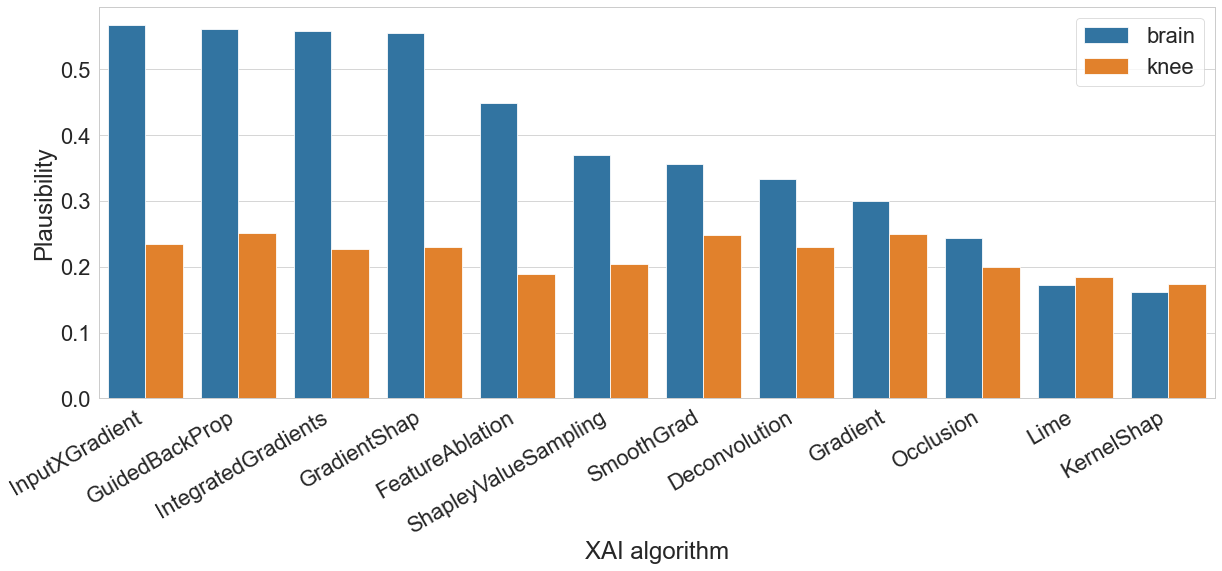

In [25]:
# barplot with plausibility ranking in brain, and another plausibility score in knee
with sns.plotting_context("paper", font_scale=2.5):

    fig, ax = plt.subplots(figsize=(20,8))

    sns.barplot(ax = ax, data=corr_plausibility_long, x="index", y='value', hue='variable', hue_order = ['brain', 'knee'], order=list(common_plausibility_rank.keys()))
    ax.set_ylabel('Plausibility')
    ax.set_xlabel('XAI algorithm')
    fig.autofmt_xdate()

    ax.legend().set_title('')
#     fig.savefig(Path('../draft')/ 'task_generalize.pdf', bbox_inches="tight")


## 2. Plausibility calculated for the model architecture by aggregating performance from each trained model

In [13]:
brain_model_wise = pd.DataFrame(msfi_fp_brain.groupby(['XAI','Fold'])['fp'].mean()).reset_index()
brain_model_wise['Task'] = 'Brain'
knee_model_wise = pd.DataFrame(msfi_fp_knee_dropna.groupby(['XAI','Fold'])['fp'].mean()).reset_index()
knee_model_wise['Task'] = 'Knee'
model_wise_plausibility = pd.concat([brain_model_wise, knee_model_wise])

In [14]:
model_wise_plausibility

,XAI,Fold,fp,Task
0,Deconvolution,1,0.417847,Brain
1,Deconvolution,2,0.343013,Brain
2,Deconvolution,3,0.260979,Brain
3,Deconvolution,4,0.280686,Brain
4,Deconvolution,5,0.364779,Brain
...,...,...,...,...
55,SmoothGrad,6,0.255077,Knee
56,SmoothGrad,7,0.241943,Knee
57,SmoothGrad,8,0.256028,Knee
58,SmoothGrad,9,0.246789,Knee


In [15]:
plausibility_rank2_brain = dict(brain_model_wise.groupby(['XAI'])['fp'].mean())
plausibility_rank2_brain = dict(sorted(plausibility_rank2_brain.items(), key=lambda x:x[1], reverse=True))
plausibility_rank2_knee = dict(knee_model_wise.groupby(['XAI'])['fp'].mean())
plausibility_rank2_knee = dict(sorted(plausibility_rank2_knee.items(), key=lambda x:x[1], reverse=True))
common_plausibility_rank2 = {k:plausibility_rank2_brain[k] for k in list(plausibility_rank2_brain.keys()) if k in list(plausibility_rank2_knee.keys())}

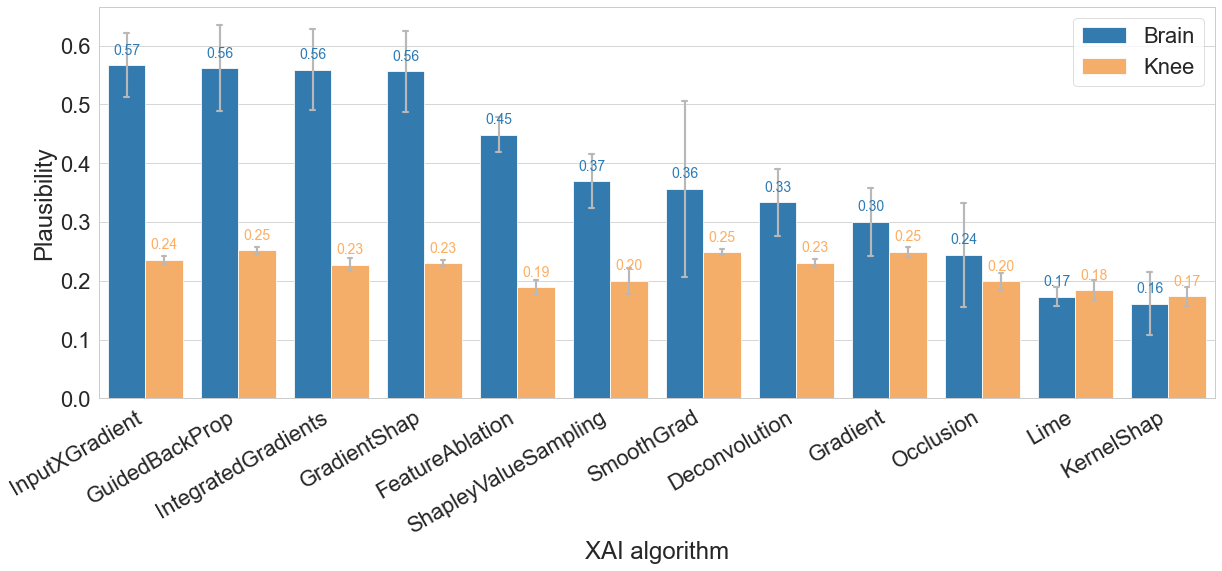

In [84]:
# barplot with plausibility ranking in brain, and another plausibility score in knee
sns.set_style("whitegrid")

b_color = '#2c7bb6'
k_color = '#fdae61'
with sns.plotting_context("paper", font_scale=2.5):

    fig, ax = plt.subplots(figsize=(20,8))

    sns.barplot(ax = ax, data=model_wise_plausibility, x="XAI", y='fp', hue='Task', 
                hue_order = ['Brain', 'Knee'], order=list(common_plausibility_rank2.keys()),
                capsize=0.05, ci='sd', errcolor='#B8B8B8', saturation=0.9, palette={"Brain": b_color, 'Knee':k_color}
               )
    ax.set_ylabel('Plausibility')
    ax.set_xlabel('XAI algorithm')
    fig.autofmt_xdate()
    ax.bar_label(ax.containers[0],fmt='%.2f',
             padding=8, color=b_color, fontsize=14)
    ax.bar_label(ax.containers[1],fmt='%.2f',
             padding=8, color=k_color, fontsize=14)

    ax.legend().set_title('')
#     fig.savefig(Path('../draft')/ 'task_generalize2.pdf', bbox_inches="tight")


In [16]:
corr_plausibility2 = pd.DataFrame.from_records([plausibility_rank2_brain, plausibility_rank2_knee], index = ['Brain', 'Knee'])
corr_plausibility2 = corr_plausibility2.transpose().dropna()
corr_plausibility2

,Brain,Knee
InputXGradient,0.566730,0.235351
GuidedBackProp,0.561325,0.251613
IntegratedGradients,0.558738,0.227093
GradientShap,0.555878,0.230038
FeatureAblation,0.448548,0.189025
ShapleyValueSampling,0.369105,0.200098
SmoothGrad,0.356310,0.248763
Deconvolution,0.333461,0.230534
Gradient,0.300168,0.249514
Occlusion,0.244159,0.199518


In [18]:
# test for assumption of Pearson correlation and t-test: normal distribution
pg.normality(corr_plausibility2['Brain']), pg.normality(corr_plausibility2['Knee'])

(              W      pval  normal
 Brain  0.896591  0.143332    True,
             W      pval  normal
 Knee  0.90484  0.183135    True)

In [49]:
# Use Pearson Correlation for reporting
pg.pairwise_corr(data = corr_plausibility2, columns = ['Brain', 'Knee'])

,X,Y,method,alternative,n,r,CI95%,p-unc,BF10,power
0,Brain,Knee,pearson,two-sided,12,0.579257,"[0.01, 0.87]",0.048411,2.044,0.537366


In [23]:
# test for assumption of t-test: Homogeneity of Variances
pg.homoscedasticity([corr_plausibility2['Brain'].tolist(), corr_plausibility2['Knee'].tolist()])

,W,pval,equal_var
levene,17.566563,0.000378,False


In [9]:
# test of assumption for t-test failed on normality test, use nonparametric test instead
pg.ttest(corr_plausibility2['Brain'], corr_plausibility2['Knee'], paired=True, alternative='greater')

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,4.210465,11,greater,0.00073,"[0.1, inf]",1.533882,58.233,0.999536


In [24]:
#  Wilcoxon signed-rank test
pg.wilcoxon(x = corr_plausibility2['Brain'], y = corr_plausibility2['Knee'], alternative = 'greater')

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,75.0,greater,0.001221,0.923077,0.8125


In [29]:
corr_plausibility2['diff'] = corr_plausibility2['Brain']-corr_plausibility2['Knee']

<Axes: xlabel='diff', ylabel='Count'>

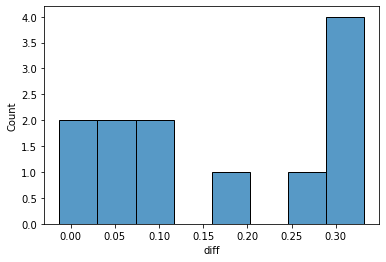

In [35]:
# The difference distribution is not symmetric in shape, 
# so do not meet the assumption of Wilcoxon signed-rank test 
# Use Sign Test instead
sns.histplot(corr_plausibility2['diff'],bins=8)

In [75]:
# Sign Test for reporting
# https://www.statsmodels.org/dev/generated/statsmodels.stats.descriptivestats.sign_test.html
from statsmodels.stats.descriptivestats import sign_test
sign_test(corr_plausibility2['diff'])

(4.0, 0.03857421875)